# Phase 1, Notebook 3: Preprocessing and Scaling

In notebook 01 we cleaned the data and in notebook 02 we made the ratio features (NLR, PLR, MLR, SII, dNLR).
The data is clean now but it is still not ready for a model. There are three problems left:

1. The features are on very different scales. PLT is in the hundreds, BASO# is usually 0.02, and the Q-flags go from 0 to 300.
2. A lot of the count features are very skewed (most values are small but a few are huge).
3. There are still missing values. We did this on purpose in cleaning, because the old "fake" values were wrong, so we turned them back into NaN.

So in this notebook we do these steps, in this order:

| Step | What we do | Learned from data? |
|---|---|---|
| 2 | log1p on the skewed count features | No, it is a fixed formula |
| 3 | Clip every feature to its 0.5% and 99.5% percentile | Yes, limits come from the development set |
| 4 | Add 3 missing flags, then fill missing values with the median | Yes, medians come from the development set |
| 5 | Standard scaling (z-score) | Yes, mean and std come from the development set |

**One important rule.** Anything that is "learned" (percentiles, medians, mean, std) is calculated **only on the development set** (train files of sites A, B and C).
Then we just apply the same numbers to the validation and test hospitals. If we calculated them on all the data, information from the test hospitals would leak into training and our results would look better than they really are.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path(".").resolve()
sys.path.insert(0, str(ROOT / "src"))
from leuko_common import FEATURES, DERIVED, LOG_FEATURES, load_clean, add_derived_features

PROC_DIR = ROOT / "data" / "processed"; PROC_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = ROOT / "reports" / "figures"; TAB_DIR = ROOT / "reports" / "tables"
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
C_HC, C_LK = "#2a78d6", "#eb6834"   # same colours as the other notebooks: healthy = blue, leukemia = orange
def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

## Step 1. Load the cleaned data and look at the scales
We load the cleaned file from notebook 01 and add the 5 ratio features from notebook 02. That gives 71 + 5 = 76 features.
The table below shows why scaling is needed. The standard deviation of SII is in the thousands, but for BASO# it is 0.42.

In [2]:
clean = load_clean(ROOT / "data" / "cleaned" / "leukoalert_cleaned.csv.gz")
df = add_derived_features(clean)                 # adds NLR, PLR, MLR, SII, dNLR (notebook 02)
ALL_FEATS = FEATURES + DERIVED                    # 71 + 5 = 76 features
LOG_COLS = [c for c in LOG_FEATURES if c in ALL_FEATS]
META = ["sample_id", "source_file", "split", "site", "cohort", "y"]
is_dev = df["cohort"] == "development"
dev = df[is_dev]
print(f"All records: {len(df):,}   development (train A, B, C): {is_dev.sum():,}   features: {len(ALL_FEATS)}")

show = ["Left Shift", "WBC", "BASO#", "NRBC#", "HGB", "MCHC", "PLT", "NE-SSC", "SII"]
dev[show].describe(percentiles=[.5]).T[["min", "50%", "max", "std"]].round(2)

All records: 446,637   development (train A, B, C): 26,922   features: 76


,min,50%,max,std
Left Shift,0.0,0.00,300.00,80.70
WBC,0.0,6.01,726.67,14.47
BASO#,0.0,0.02,23.37,0.42
NRBC#,0.0,0.00,21.12,0.31
HGB,27.0,103.00,208.00,26.67
MCHC,234.0,328.00,497.00,15.61
PLT,0.0,167.00,2656.00,124.55
NE-SSC,95.0,151.40,241.00,9.81
SII,0.0,555.31,255692.00,3623.60


Looking at this table: PLT goes up to 2656 and SII goes up to more than 250,000, while BASO# and NRBC# are almost always close to 0.
Logistic Regression works with the numbers directly, so a feature with big numbers would look more "important" just because of its units. Scaling fixes this.

## Step 2. Log transform for skewed features
In notebook 01 we saw that the count features (WBC, the absolute cell counts, PLT, IG#, NRBC# and also the ratios) have a long tail to the right.
We use `log1p(x) = log(1 + x)` instead of plain `log(x)`, because some values are exactly 0 and log(0) does not exist.
The list of these 34 features is `LOG_FEATURES` in `src/leuko_common.py`. It is the same list the Logistic Regression code uses, so everything stays consistent.

In [3]:
skew_before = dev[LOG_COLS].skew()
logged = dev[LOG_COLS].clip(lower=0).pipe(np.log1p)
skew_after = logged.skew()
sk = pd.DataFrame({"skew_before": skew_before, "skew_after_log1p": skew_after}).sort_values("skew_before", ascending=False)
print(f"{len(LOG_COLS)} features get log1p. Median skewness before: {skew_before.median():.1f}, after: {skew_after.median():.1f}")
print("Features where skewness is still above 2 after the log:", ", ".join(sk.index[sk.skew_after_log1p.abs() > 2]) or "none")
sk.head(12).round(2)

34 features get log1p. Median skewness before: 20.8, after: 1.8
Features where skewness is still above 2 after the log: HFLC#, BA-D#, LYMPH#&, LYMPH#, IG#, NRBC#, BASO#, BA-N#, EO#, NRBC%, MONO#, MLR, HFLC%, BA-D%


,skew_before,skew_after_log1p
HFLC#,145.47,19.60
BA-D#,65.55,19.33
LYMPH#&,63.24,2.12
LYMPH#,62.35,2.12
IG#,45.49,7.39
NRBC#,40.51,13.58
BASO#,40.19,26.00
BA-N#,37.95,20.97
EO#,36.40,6.46
NRBC%,34.92,4.04


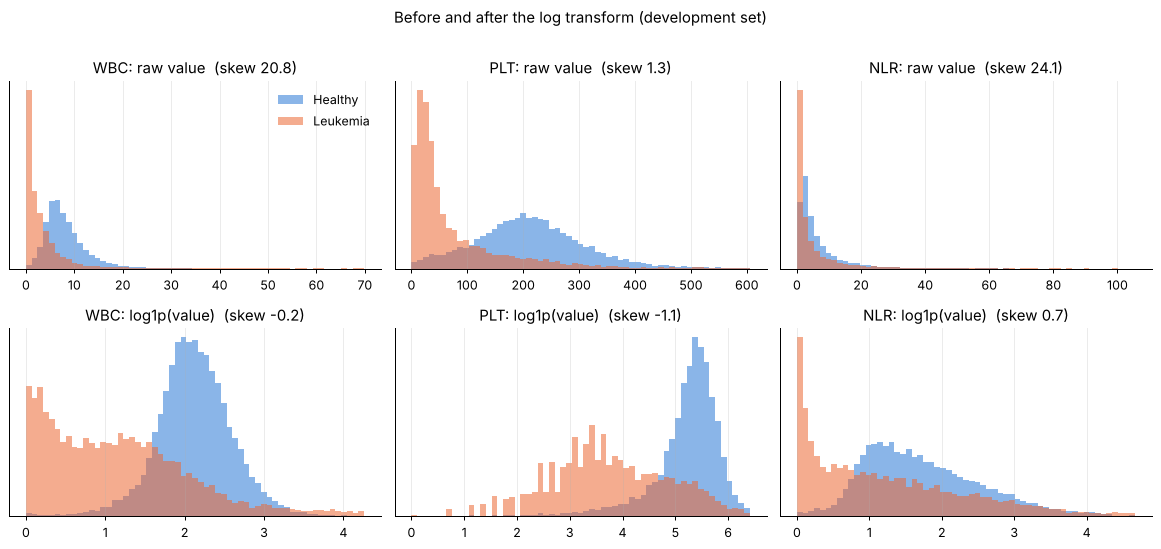

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for j, f in enumerate(["WBC", "PLT", "NLR"]):
    s = dev[[f, "y"]].dropna()
    for i, (vals, lab) in enumerate([(s[f], "raw value"), (np.log1p(s[f].clip(lower=0)), "log1p(value)")]):
        ax = axes[i, j]
        bins = np.linspace(*np.nanpercentile(vals, [0, 99.5]), 60)
        for k, c, name in [(0, C_HC, "Healthy"), (1, C_LK, "Leukemia")]:
            ax.hist(vals[s.y == k], bins=bins, density=True, alpha=.55, color=c, label=name)
        ax.set_title(f"{f}: {lab}  (skew {vals.skew():.1f})"); ax.set_yticks([])
axes[0, 0].legend(frameon=False)
fig.suptitle("Before and after the log transform (development set)", y=1.01)
plt.tight_layout(); savefig("P1_log_transform_before_after"); plt.show()

**What we see.** The median skewness went down from about 21 to about 2, so the log helped a lot. WBC is the best example. On the raw scale almost everything is squeezed near 0,
but after the log you can clearly see the healthy hump around 2 and the leukemia values spread out on both sides (very low and very high WBC).

Two things we noticed:
* 14 of the 34 features still have a skewness above 2 after the log, for example BASO# and HFLC#. Their normal values are tiny (like 0.02) and log(1 + 0.02) is almost the same as 0.02, so the log can't do much there. Step 3 (clipping) handles their extreme values.
* PLT was not very skewed to begin with (skew 1.3) and after the log it leans a bit the other way (−1.1). We still kept it in the list, because the log spreads out the very low platelet counts, and low platelets are one of the strongest signs of leukemia in our EDA.

## Step 3. Clip the extreme values
In notebook 01 we decided **not to delete outliers**, because most of the extreme values are leukemia patients (for example WBC of 700). Deleting them would delete the disease.
But one huge value can still pull a linear model too much. So instead of deleting, we **clip**: anything below the 0.5th percentile becomes the 0.5th percentile, and anything above the 99.5th percentile becomes the 99.5th percentile.
The row stays in the data, only the extreme number is made smaller. The percentiles come from the development set only.

In [5]:
Z = df[ALL_FEATS].astype(float).copy()
Z[LOG_COLS] = np.log1p(Z[LOG_COLS].clip(lower=0))
lo = Z[is_dev].quantile(0.005); hi = Z[is_dev].quantile(0.995)       # learned on development ONLY
clipped = (Z.lt(lo) | Z.gt(hi)) & Z.notna()
Z = Z.clip(lo, hi, axis=1)
clip_tab = (clipped.groupby(df["cohort"]).apply(lambda g: g.to_numpy().sum() / g.size * 100)).rename("% of cells clipped").round(3)
display(clip_tab)
print(f"Leukemia share among clipped development cells: {100*df.loc[is_dev, 'y'].values.repeat(len(ALL_FEATS))[clipped[is_dev].to_numpy().ravel()].mean():.1f}% (baseline 33.3%)")

,% of cells clipped
cohort,
development,0.705
external_validation,0.406
internal_validation,0.382
real_world_test,0.324


Leukemia share among clipped development cells: 72.6% (baseline 33.3%)


**What we see.** Less than 1% of the values were changed in every cohort. In the development set, 72.6% of the clipped values belong to leukemia records, while only 33.3% of records are leukemia.
This shows again that the extreme values are mostly the disease and not mistakes, so clipping (and not deleting) was the right choice.

## Step 4. Missing values: flags first, then the median
In notebook 01 we found that missing values are **not random**. When the analyser could not do the differential count, the patient was much more likely to have leukemia.
If we just fill the gaps, the model loses that information. So before filling, we add three 0/1 columns that remember where the big blocks of data were missing:

* `MISSING_differential`: the white cell differential (NEUT%, LYMPH% and so on) was not reported
* `MISSING_platelet_indices`: MPV, PDW, P-LCR and PCT were not reported
* `MISSING_cell_population`: the cell population numbers (NE-SSC and the others) were not reported

Then every missing value is filled with the **median** of that feature in the development set. We used the median and not the mean, because the median is not pulled by extreme values.

In [6]:
FLAG_SOURCES = {"MISSING_differential": "NEUT%", "MISSING_platelet_indices": "MPV", "MISSING_cell_population": "NE-SSC"}
flags = pd.DataFrame({name: df[col].isna().astype(int) for name, col in FLAG_SOURCES.items()})
flag_tab = pd.DataFrame({
    "% missing (development)": flags[is_dev].mean().mul(100).round(2),
    "leukemia rate when missing (dev) %": [round(100 * df.loc[is_dev & (flags[c] == 1), "y"].mean(), 1) for c in flags],
    "leukemia rate when present (dev) %": [round(100 * df.loc[is_dev & (flags[c] == 0), "y"].mean(), 1) for c in flags]})
display(flag_tab)

medians = Z[is_dev].median()                                           # learned on development ONLY
n_missing_before = int(Z.isna().sum().sum())
Z = Z.fillna(medians)
print(f"Missing cells filled with the development median: {n_missing_before:,}. Missing cells left: {int(Z.isna().sum().sum())}")

,% missing (development),leukemia rate when missing (dev) %,leukemia rate when present (dev) %
MISSING_differential,2.01,92.4,32.1
MISSING_platelet_indices,13.41,71.4,27.4
MISSING_cell_population,2.16,92.8,32.0


Missing cells filled with the development median: 270,226. Missing cells left: 0


**What we see.** The flags really carry information. In the development set, when the differential is missing, 92.4% of those records are leukemia, compared to 32.1% when it is present.
Missing platelet indices give 71.4% compared to 27.4%. After filling, there are no missing values left.

## Step 5. Standard scaling
Now we scale every feature with the z-score: `z = (x − mean) / std`. After this every feature has mean 0 and standard deviation 1 in the development set, so they are all on the same scale.

**Why standard scaling and not min-max scaling?** Min-max puts everything between 0 and 1 using the smallest and biggest value. Our data has very big leukemia values, so with min-max most normal patients would be squeezed into a tiny part near 0.
Standard scaling (after the log and the clipping) does not have this problem.

The 3 missing flags are not scaled, they stay 0 or 1 so they are easy to read.

In [7]:
mean_, std_ = Z[is_dev].mean(), Z[is_dev].std(ddof=0)                  # learned on development ONLY
std_ = std_.replace(0, 1.0)
S = (Z - mean_) / std_
chk = pd.DataFrame({"mean (dev)": S[is_dev].mean(), "std (dev)": S[is_dev].std(ddof=0)})
print(f"After scaling, development set: mean between {chk['mean (dev)'].min():.3f} and {chk['mean (dev)'].max():.3f}, "
      f"std between {chk['std (dev)'].min():.3f} and {chk['std (dev)'].max():.3f}")
other = (S.groupby(df["cohort"]).mean().T[["internal_validation", "external_validation", "real_world_test"]]
         .loc[["WBC", "LYMPH%", "HGB", "PLT", "MPV", "NE-SSC"]].round(2))
print("Mean of the scaled values in the other cohorts (0 would mean 'same as development'):")
other

After scaling, development set: mean between -0.000 and 0.000, std between 1.000 and 1.000
Mean of the scaled values in the other cohorts (0 would mean 'same as development'):


cohort,internal_validation,external_validation,real_world_test
WBC,0.34,0.25,0.30
LYMPH%,-0.15,-0.04,-0.19
HGB,0.40,0.54,0.43
PLT,0.40,0.47,0.34
MPV,-0.14,-0.21,-0.01
NE-SSC,0.26,0.10,0.17


**What we see.** In the development set every feature now has mean 0 and std 1, so the scaling worked.

In the other cohorts the means are not exactly 0. For example HGB and PLT are about +0.3 to +0.5. This is expected and it is not a mistake.
The development files have 33% leukemia, but the validation and test hospitals have only about 4%. Leukemia patients have low HGB and low PLT, so a group with fewer leukemia patients has higher HGB and PLT on average.
A small part of the difference is also because hospitals measure things a bit differently (we saw this "site shift" in notebook 01). We do **not** rescale these hospitals with their own numbers, because in real life a new hospital's data would not be available while training.

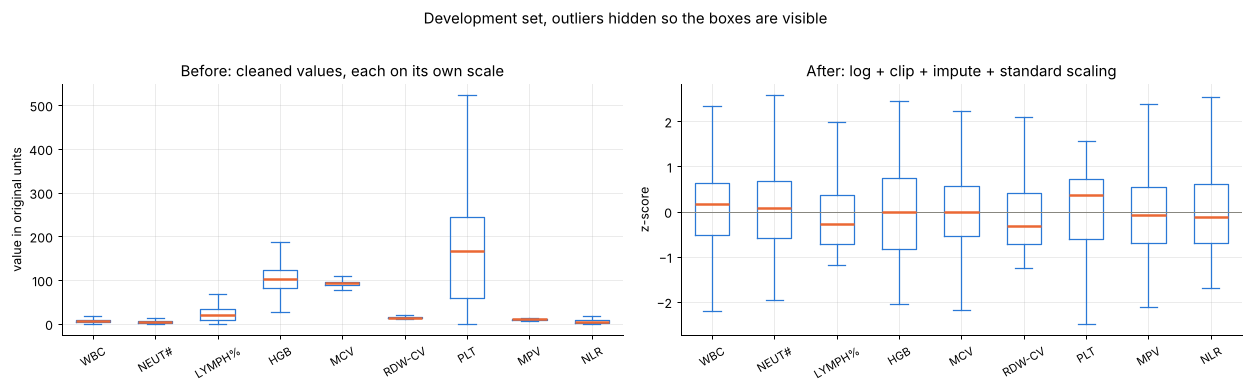

In [8]:
feat_plot = ["WBC", "NEUT#", "LYMPH%", "HGB", "MCV", "RDW-CV", "PLT", "MPV", "NLR"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
d0 = dev[feat_plot]
ax[0].boxplot([d0[c].dropna() for c in feat_plot], tick_labels=feat_plot, showfliers=False, widths=.55,
              medianprops=dict(color=C_LK, lw=2), boxprops=dict(color=C_HC), whiskerprops=dict(color=C_HC), capprops=dict(color=C_HC))
ax[0].set_title("Before: cleaned values, each on its own scale"); ax[0].set_ylabel("value in original units")
s0 = S.loc[is_dev, feat_plot]
ax[1].boxplot([s0[c] for c in feat_plot], tick_labels=feat_plot, showfliers=False, widths=.55,
              medianprops=dict(color=C_LK, lw=2), boxprops=dict(color=C_HC), whiskerprops=dict(color=C_HC), capprops=dict(color=C_HC))
ax[1].axhline(0, color="#888780", lw=.8); ax[1].set_title("After: log + clip + impute + standard scaling"); ax[1].set_ylabel("z-score")
for a in ax: a.tick_params(axis="x", labelsize=9, rotation=30)
fig.suptitle("Development set, outliers hidden so the boxes are visible", y=1.02)
plt.tight_layout(); savefig("P2_scaling_before_after"); plt.show()

The right picture shows that after preprocessing all features sit around 0 with a similar spread, so no feature is bigger just because of its unit.

## Step 6. Save the processed data and the numbers we learned
We save:
* `data/processed/processed_development.csv.gz`: the development set after all the steps (in the GitHub repo)
* `data/processed/processed_all_cohorts.csv.gz`: all 446,637 records after all the steps. This file is about 92 MB, so it is **not** uploaded to GitHub. Running this notebook makes it again in less than a minute.
* `data/processed/preprocessing_params.csv` and `.joblib`: for every feature, whether it was logged, the clip limits, the median, the mean and the std. With these numbers anyone can apply exactly the same preprocessing to new data.

In [9]:
processed = pd.concat([df[META].reset_index(drop=True), S.round(5).reset_index(drop=True), flags.reset_index(drop=True)], axis=1)
params = pd.DataFrame({"log1p": [c in LOG_COLS for c in ALL_FEATS], "clip_low": lo, "clip_high": hi,
                       "median": medians, "mean": mean_, "std": std_}, index=ALL_FEATS)
params.index.name = "feature"
params.round(6).to_csv(PROC_DIR / "preprocessing_params.csv")
joblib.dump({"features": ALL_FEATS, "log_cols": LOG_COLS, "clip_low": lo, "clip_high": hi, "median": medians,
             "mean": mean_, "std": std_, "flag_sources": FLAG_SOURCES}, PROC_DIR / "preprocessing_params.joblib")
processed[processed.cohort == "development"].to_csv(PROC_DIR / "processed_development.csv.gz", index=False, compression="gzip")
processed.to_csv(PROC_DIR / "processed_all_cohorts.csv.gz", index=False, compression="gzip")
print("Processed table:", processed.shape, "=", len(META), "info columns +", len(ALL_FEATS), "scaled features +", flags.shape[1], "missing flags")
print("Any missing values left:", bool(processed[ALL_FEATS + list(flags)].isna().any().any()))
for p in sorted(PROC_DIR.iterdir()):
    print(f"  {p.name:38s} {p.stat().st_size/1e6:7.2f} MB")
params.loc[["WBC", "HGB", "PLT", "NLR"]].round(3)

Processed table: (446637, 85) = 6 info columns + 76 scaled features + 3 missing flags
Any missing values left: False
  preprocessing_params.csv                  0.00 MB
  preprocessing_params.joblib               0.01 MB
  processed_all_cohorts.csv.gz             91.91 MB
  processed_development.csv.gz              5.54 MB


,log1p,clip_low,clip_high,median,mean,std
feature,,,,,,
WBC,True,0.020,4.261,1.947,1.821,0.798
HGB,False,49.000,168.000,103.000,102.996,26.486
PLT,True,1.386,6.407,5.124,4.739,1.070
NLR,True,0.000,4.668,1.479,1.592,0.937


## Summary

* We log-transformed 34 skewed count features. The median skewness went from about 21 to about 2.
* We clipped the extreme values at the 0.5% and 99.5% percentiles instead of deleting them, because most of them are leukemia patients. Less than 1% of values changed.
* We added 3 missing flags, because missing blocks are a strong sign (92% leukemia when the differential is missing), and then filled the gaps with the development median.
* We standard-scaled all 76 features. All the numbers were learned on the development set only and then applied to the other hospitals.
* The final table has 446,637 rows and 85 columns (6 info columns, 76 scaled features, 3 flags) with no missing values.

**Note for Phase 2 (modelling).** When we do cross-validation, the model code (`src/lr_pipeline.py`) repeats exactly these steps **inside each training fold**, so even the validation fold inside the development set is never used to learn the medians or the scaling.
The file saved here is the "ready to use" version of the data for quick checks and for anyone who wants to try a model without writing the preprocessing again.